# COU 07506 Digital Signal Processing — Week 04: z-Transform Laboratory: Poles, Zeros and Stability

**Name:** ............................  **Registration No.:** ..................  
**Class:** BEng24 ......  **Group:** ......  **Date:** ............  
**Instructor checkpoints signed:** [ ] 1 [ ] 2 [ ] 3 [ ] 4

**Unit 2** — z-transform, ROC, inverse z-transform, stability · **Handout:** §2.2–2.4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab

**(a)** $H(z) = \dfrac{1}{1 - 0.9z^{-1} + 0.81z^{-2}} = \dfrac{z^2}{z^2 - 0.9z + 0.81}$. Poles:

$$z = \frac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = 0.45 \pm j0.779 = 0.9\,e^{\pm j\pi/3}$$

Both poles have $|p| = \sqrt{0.81} = 0.9 < 1$ (inside the unit circle), so the causal system is **stable**.

**(b)** $X(z) = \dfrac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})} = \dfrac{A}{1 - 0.5z^{-1}} + \dfrac{B}{1 - 0.25z^{-1}}$

$$A = \left.\frac{1}{1 - 0.25z^{-1}}\right|_{z=0.5} = \frac{1}{1 - 0.5} = 2, \qquad B = \left.\frac{1}{1 - 0.5z^{-1}}\right|_{z=0.25} = \frac{1}{1 - 2} = -1$$

$$X(z) = \frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}} \;\Rightarrow\; x(n) = \left[2(0.5)^n - (0.25)^n\right]u(n)$$

In [2]:
# Numerical check of the pre-lab
p = np.roots([1, -0.9, 0.81])
print("pre-lab (a) poles:", p, " |p| =", np.abs(p), " angle (deg) =", np.degrees(np.angle(p)), " stable:", np.all(np.abs(p) < 1))

pre-lab (a) poles: [0.45+0.77942286j 0.45-0.77942286j]  |p| = [0.9 0.9]  angle (deg) = [ 60. -60.]  stable: True


## Task 4.1 — A pole-zero plotting function

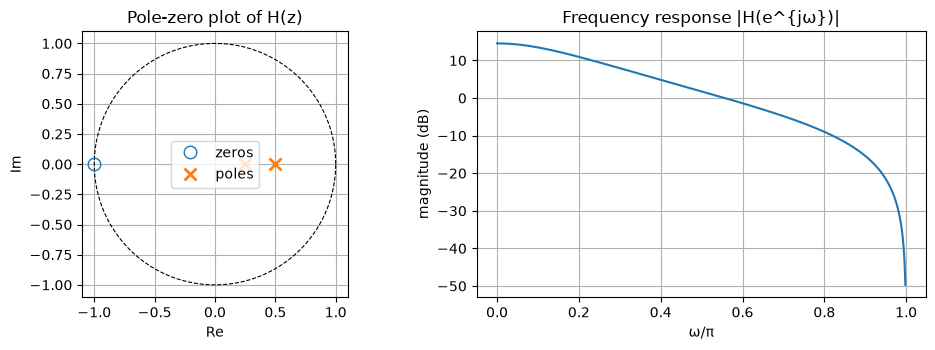

zeros: [-1.]  poles: [0.5  0.25]  stable: True


In [3]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.grid(True)
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot of H(z)")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π"); ax2.set_ylabel("magnitude (dB)"); ax2.set_title("Frequency response |H(e^{jω})|")
ax2.grid(True)
plt.tight_layout(); plt.show()
print("zeros:", z, " poles:", p, " stable:", np.all(np.abs(p) < 1))

**Observation.** $H(z) = \dfrac{1 + z^{-1}}{1 - 0.75z^{-1} + 0.125z^{-2}}$ has a zero at $z = -1$ (on the unit circle, so the response has a null at $\omega = \pi$) and real poles at $z = 0.5$ and $z = 0.25$, both inside the unit circle, so the system is stable. The poles are on the positive real axis, so the response is strongest at low frequency (low-pass shape).

## Task 4.2 — Inverse z-transform with `residuez`

In [4]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("partial fractions == lfilter:", np.allclose(x_pf, x_lf))

# Repeat for the system of Task 4.1 (b = [1, 1])
r1, p1, k1 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("\nTask 4.1 system: residues", r1, "poles", p1)
h_pf = sum(ri * pi**n for ri, pi in zip(r1, p1)).real
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
h_cf = 6*0.5**n - 5*0.25**n
print("partial fractions == lfilter   :", np.allclose(h_pf, h_lf))
print("partial fractions == closed form 6(0.5)^n - 5(0.25)^n:", np.allclose(h_pf, h_cf))

residues [-1.  2.] poles [0.25 0.5 ]
partial fractions == lfilter: True

Task 4.1 system: residues [-5.  6.] poles [0.25 0.5 ]
partial fractions == lfilter   : True
partial fractions == closed form 6(0.5)^n - 5(0.25)^n: True


**Observation.** For $1/(1 - 0.75z^{-1} + 0.125z^{-2})$ the poles are $0.5$ and $0.25$. The residues are $2$ (for the pole at 0.5) and $-1$ (for the pole at 0.25), which matches my pre-lab answer (b), since that $X(z)$ has the same denominator: $(1-0.5z^{-1})(1-0.25z^{-1}) = 1 - 0.75z^{-1} + 0.125z^{-2}$. With $b = [1, 1]$ the residues become $6$ and $-5$, which gives $h(n) = 6(0.5)^n - 5(0.25)^n$, as confirmed by the closed-form comparison above. (Note `residuez` lists the poles in its own order, here $0.25$ first, so read each residue next to its pole.)

## Task 4.3 — Pole position and the impulse response

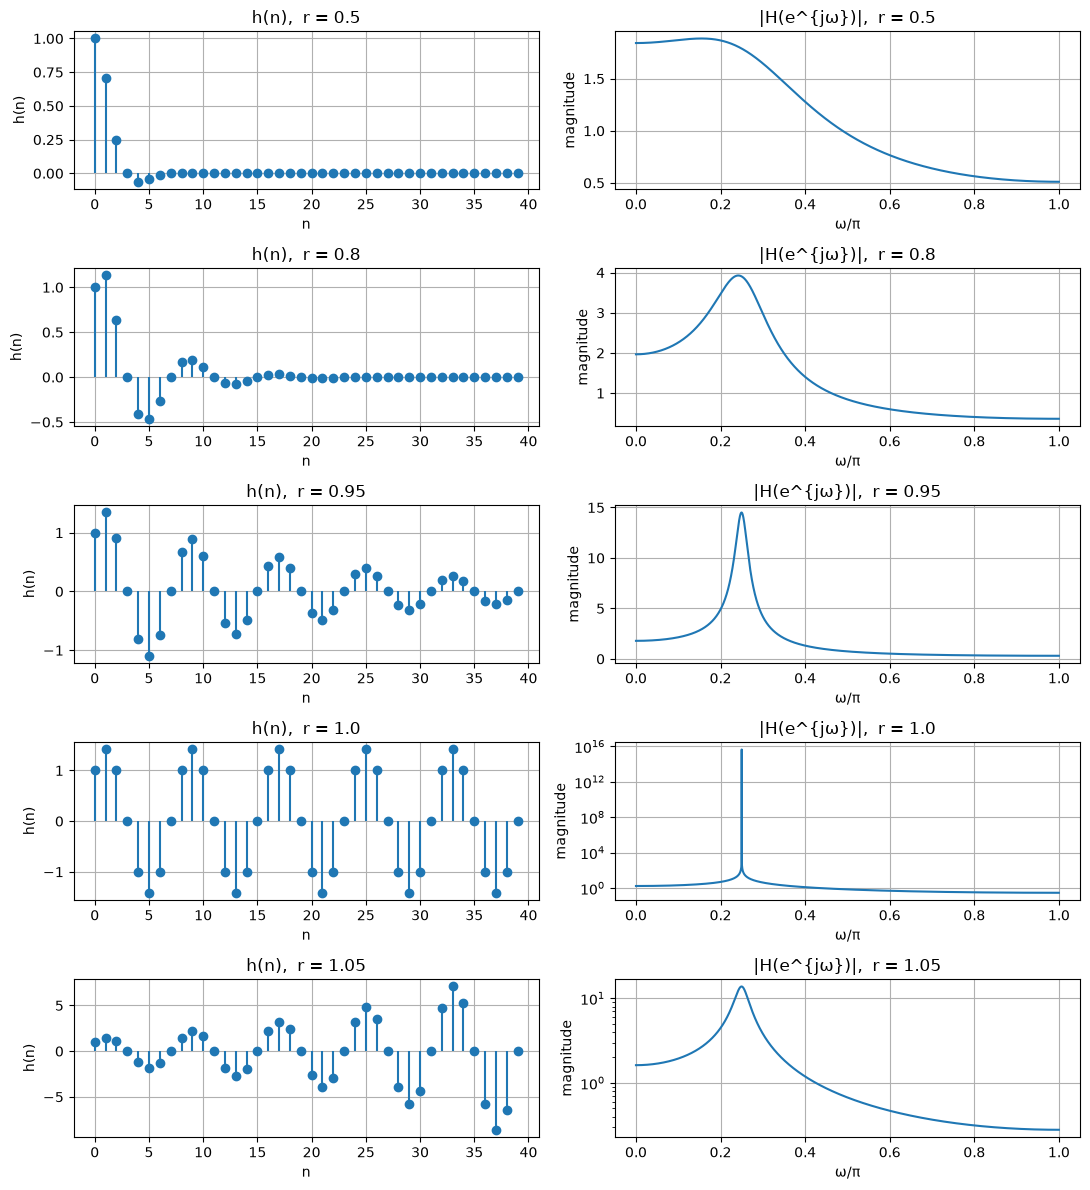

    r  |pole|     peak |H|  peak at ω/π  -3 dB width (ω/π)  max|h| last 10
 0.50    0.50         1.89        0.155              0.385        9.31e-10
 0.80    0.80         3.93        0.242              0.154         0.00124
 0.95    0.95         14.5        0.250              0.033            0.26
 1.00    1.00     4.42e+15        0.250              0.000            1.41
 1.05    1.05         13.8        0.250              0.031             8.6


In [5]:
rs = [0.5, 0.8, 0.95, 1.0, 1.05]
N = 40
imp = np.zeros(N); imp[0] = 1.0
fig, axes = plt.subplots(len(rs), 2, figsize=(11, 12))
rows = []
for i, r in enumerate(rs):
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    h = signal.lfilter([1], a, imp)
    w, H = signal.freqz([1], a, worN=8192)
    mag = np.abs(H)
    axes[i, 0].stem(np.arange(N), h, basefmt=" ")
    axes[i, 0].set_title(f"h(n),  r = {r}"); axes[i, 0].set_xlabel("n"); axes[i, 0].set_ylabel("h(n)"); axes[i, 0].grid(True)
    axes[i, 1].plot(w/np.pi, mag)
    axes[i, 1].set_title(f"|H(e^{{jω}})|,  r = {r}"); axes[i, 1].set_xlabel("ω/π"); axes[i, 1].set_ylabel("magnitude"); axes[i, 1].grid(True)
    if r >= 1:   # frequency response plot is not meaningful as a stable response
        axes[i, 1].set_yscale("log")
    pk = mag.max(); bw = w[mag >= pk/np.sqrt(2)]
    rows.append((r, abs(np.roots(a)[0]), pk, w[mag.argmax()]/np.pi, (bw.max()-bw.min())/np.pi, np.max(np.abs(h[-10:]))))
plt.tight_layout(); plt.show()

print(f"{'r':>5} {'|pole|':>7} {'peak |H|':>12} {'peak at ω/π':>12} {'-3 dB width (ω/π)':>18} {'max|h| last 10':>15}")
for r, pm, pk, wp, bw, hl in rows:
    print(f"{r:5.2f} {pm:7.2f} {pk:12.3g} {wp:12.3f} {bw:18.3f} {hl:15.3g}")

**Description.**
- **Decay:** $h(n) = \dfrac{r^n \sin\!\big((n+1)\pi/4\big)}{\sin(\pi/4)}\,u(n)$ is a sinusoid at $\pi/4$ rad/sample inside an envelope $r^n$. For $r = 0.5$ it dies away in a few samples, for $0.8$ it takes roughly 20 to 30, and for $0.95$ it lasts the whole 40 samples.
- **Oscillation:** the oscillation frequency stays at $\pi/4$ (8 samples per cycle) for every $r$, because only the pole radius changes, not its angle.
- **Peak sharpness:** the resonance peak near $\omega = \pi/4$ (i.e. $\omega/\pi = 0.25$) gets taller and narrower as $r \to 1$: the peak height grows from about 1.9 to 3.9 to 14.5 and the $-3$ dB width shrinks from 0.385 to 0.154 to 0.033 (in units of $\pi$). For small $r$ the peak is also pulled slightly below $\pi/4$.
- **Unstable values:** $r = 1.05$ is **unstable**: the envelope $1.05^n$ grows without bound. $r = 1.0$ puts the poles *on* the unit circle: $h(n)$ keeps oscillating with constant amplitude and never decays, so the system is not BIBO stable (marginal). Only $r = 0.5, 0.8, 0.95$ are stable. For $r \ge 1$ the plotted $|H|$ is not a valid frequency response of a stable system (at $r = 1$ it is infinite at $\pi/4$, and for $r = 1.05$ the DTFT of the growing $h(n)$ does not exist).

## Task 4.4 — Stability of given systems

system                                      max |pole|  poles in |z|<1  max|h| last 20  verdict
(a) H1 = 1/(1 - 1.6z^-1 + 0.89z^-2)             0.9434            True        4.64e-05  stable
(b) H2 = (1 + z^-1)/(1 - 2.5z^-1 + z^-2)        2.0000           False        1.61e+60  UNSTABLE
(c) H3 = 1/(1 + 0.5z^-1 - 0.5z^-2)              1.0000           False           0.667  NOT stable (pole on unit circle)
(d) H4 = 1 - z^-4                               0.0000            True               0  stable


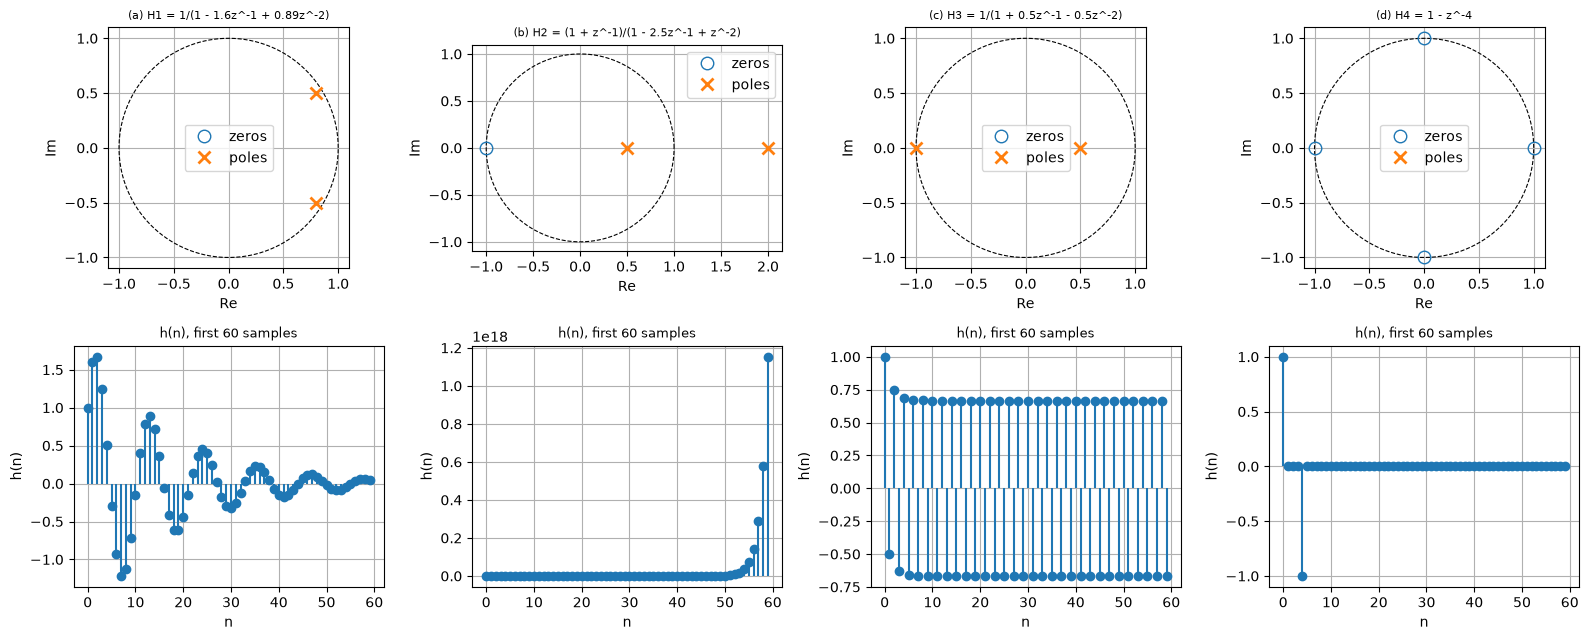

In [6]:
systems = {
    "(a) H1 = 1/(1 - 1.6z^-1 + 0.89z^-2)":         ([1],       [1, -1.6, 0.89]),
    "(b) H2 = (1 + z^-1)/(1 - 2.5z^-1 + z^-2)":    ([1, 1],    [1, -2.5, 1.0]),
    "(c) H3 = 1/(1 + 0.5z^-1 - 0.5z^-2)":          ([1],       [1, 0.5, -0.5]),
    "(d) H4 = 1 - z^-4":                           ([1, 0, 0, 0, -1], [1]),
}
N = 200
imp = np.zeros(N); imp[0] = 1.0

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
print(f"{'system':<42} {'max |pole|':>11} {'poles in |z|<1':>15} {'max|h| last 20':>15}  verdict")
for j, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[0, j])
    axes[0, j].set_title(name, fontsize=8)
    h = signal.lfilter(b, a, imp)
    axes[1, j].stem(np.arange(60), h[:60], basefmt=" ")
    axes[1, j].set_title("h(n), first 60 samples", fontsize=9); axes[1, j].set_xlabel("n"); axes[1, j].set_ylabel("h(n)"); axes[1, j].grid(True)
    maxp = np.max(np.abs(p)) if len(p) else 0.0
    tail = np.max(np.abs(h[-20:]))
    if len(p) == 0 or maxp < 1 - 1e-9:
        verdict = "stable"
    elif abs(maxp - 1) <= 1e-9:
        verdict = "NOT stable (pole on unit circle)"
    else:
        verdict = "UNSTABLE"
    print(f"{name:<42} {maxp:11.4f} {str(bool(np.all(np.abs(p) < 1))):>15} {tail:15.3g}  {verdict}")
plt.tight_layout(); plt.show()

**Classification.**

| system | poles | stable? | check with $h(n)$ |
|---|---|---|---|
| (a) $H_1$ | $0.8 \pm j0.5$, $\lvert p\rvert = \sqrt{0.89} = 0.943$ | **Stable** | $h(n)$ is an oscillation decaying to zero |
| (b) $H_2$ | $2$ and $0.5$ | **Unstable** (pole at $z=2$) | $h(n)$ grows without bound (like $2^n$) |
| (c) $H_3$ | $-1$ and $0.5$ | **Not BIBO stable** (pole *on* the unit circle at $z=-1$) | $h(n)$ does not decay: it keeps an alternating $(-1)^n$ component of constant size |
| (d) $H_4 = 1 - z^{-4}$ | none except $z=0$ (FIR) | **Stable** | $h(n) = \{1,0,0,0,-1\}$, finite length |

Note that (c) is a trap: it looks "almost stable" but a pole at $|z|=1$ is not strictly inside the unit circle, so a bounded input such as $(-1)^n$ can produce an unbounded output. The FIR system (d) is always stable; its four zeros are on the unit circle ($z^4 = 1$), which creates nulls but does not affect stability.

## Task 4.5 — Design a resonator

theta = 0.250 pi rad, a = [ 1.     -1.3718  0.9409], b = [ 0.0296  0.     -0.0296]
peak at 1001.0 Hz
-3 dB band: 963 Hz to 1039 Hz (width about 76 Hz)


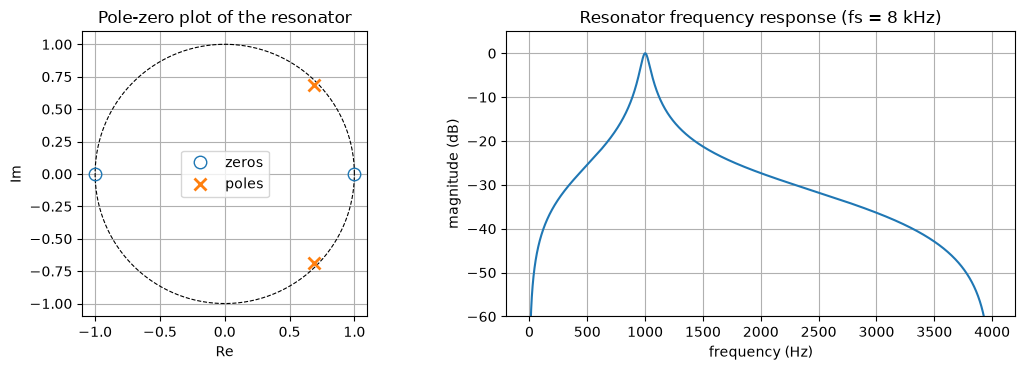

In [7]:
fs = 8000
f0 = 1000.0
r = 0.97
theta = 2*np.pi*f0/fs                      # = pi/4

# poles r e^{±jθ}; zeros at z = +1 and z = -1  ->  (1 - z^-1)(1 + z^-1) = 1 - z^-2
a = [1, -2*r*np.cos(theta), r**2]
b = [1, 0, -1]

# scale so the peak gain is 0 dB
w, H = signal.freqz(b, a, worN=4096, fs=fs)
gain = np.abs(H).max()
b = np.array(b)/gain
w, H = signal.freqz(b, a, worN=4096, fs=fs)
print(f"theta = {theta/np.pi:.3f} pi rad, a = {np.round(a, 4)}, b = {np.round(b, 4)}")
print(f"peak at {w[np.abs(H).argmax()]:.1f} Hz")
bw = w[np.abs(H) >= 1/np.sqrt(2)]
print(f"-3 dB band: {bw.min():.0f} Hz to {bw.max():.0f} Hz (width about {bw.max()-bw.min():.0f} Hz)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot of the resonator")
ax2.plot(w, 20*np.log10(np.abs(H) + 1e-12))
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("magnitude (dB)")
ax2.set_title("Resonator frequency response (fs = 8 kHz)")
ax2.set_ylim(-60, 5); ax2.grid(True)
plt.tight_layout(); plt.show()

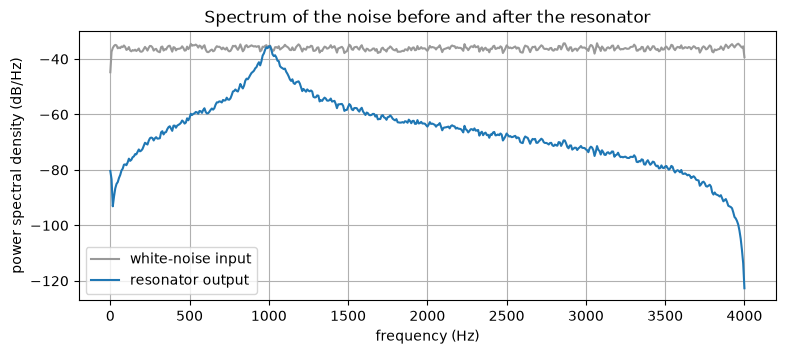

output peak near 1007.8125 Hz
input (white noise):


output (resonator, 1 kHz):


In [8]:
# Apply to white noise
rng = np.random.default_rng(0)
x = rng.standard_normal(3*fs)               # 3 s of white noise
y = signal.lfilter(b, a, x)

f_x, Px = signal.welch(x, fs=fs, nperseg=1024)
f_y, Py = signal.welch(y, fs=fs, nperseg=1024)
plt.figure()
plt.plot(f_x, 10*np.log10(Px), color="0.6", label="white-noise input")
plt.plot(f_y, 10*np.log10(Py), label="resonator output")
plt.xlabel("frequency (Hz)"); plt.ylabel("power spectral density (dB/Hz)")
plt.title("Spectrum of the noise before and after the resonator")
plt.legend(); plt.grid(True); plt.show()

print("output peak near", f_y[np.argmax(Py)], "Hz")
print("input (white noise):");     display(Audio(x, rate=fs))
print("output (resonator, 1 kHz):"); display(Audio(y, rate=fs))

**Design.** A resonance at $f_0 = 1$ kHz with $f_s = 8$ kHz means $\theta = 2\pi f_0/f_s = \pi/4$, so the poles are $0.97\,e^{\pm j\pi/4}$ and $A(z) = 1 - 2(0.97)\cos(\pi/4)z^{-1} + 0.97^2 z^{-2}$. The zeros at $z = \pm 1$ give $B(z) = (1 - z^{-1})(1 + z^{-1}) = 1 - z^{-2}$. The gain is scaled so the peak is 0 dB.

**Result.** The measured peak is at about 1 kHz and the $-3$ dB band is narrow (printed above, about 76 Hz wide, which agrees with the rule of thumb bandwidth $\approx 2(1-r)$ rad/sample $= 0.06$ rad $\approx 76$ Hz), with deep nulls at 0 Hz and 4 kHz. White noise has a flat spectrum, and the output spectrum shows a single peak at 1 kHz, so the output sounds like a tone-like "whistling" noise centred on 1 kHz.

## Analysis questions

**1. Effect of $r$ on the bandwidth of the resonance (Task 4.3).** As $r \to 1$ the poles move toward the unit circle, so the peak at $\omega \approx \pi/4$ becomes taller and narrower: the $-3$ dB bandwidth falls from about $0.385\pi$ at $r = 0.5$ to $0.154\pi$ at $r = 0.8$ and $0.033\pi$ at $r = 0.95$. As a rule of thumb, the bandwidth is about $2(1 - r)$ rad/sample (so $0.1$ rad at $r = 0.95$, which matches the measured $0.033\pi \approx 0.104$). The price of a sharper resonance is a longer-lasting impulse response (the envelope $r^n$ decays more slowly), so $h(n)$ rings for longer.

**2. What happens to $h(n)$ when a pole lies exactly on the unit circle?** The envelope $r^n$ equals 1, so $h(n)$ neither decays nor grows. For a complex pair at $e^{\pm j\theta}$ it is a sustained sinusoid of constant amplitude; for a real pole at $z = 1$ or $z = -1$ it is a constant or an alternating $\pm1$ sequence. The impulse response is then not absolutely summable, so the system is not BIBO stable (it is called marginally stable). An input at the pole frequency makes the output grow without bound (resonance).

**3. Why do zeros at $z = \pm 1$ make the resonator a band-pass filter?** A zero on the unit circle forces $H = 0$ at that frequency. $z = 1$ is $\omega = 0$ (DC) and $z = -1$ is $\omega = \pi$ ($f_s/2$), so the response is zero at both ends of the band. The pole pair near $\omega = \pi/4$ gives a gain peak in the middle. Zero at DC, peak in the middle, zero at $f_s/2$: that is a band-pass shape.

**4. Check Task 4.4 (a)–(c) with the stability triangle.** For $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$ the system is stable if and only if $|a_2| < 1$ and $|a_1| < 1 + a_2$.

- **(a)** $a_1 = -1.6$, $a_2 = 0.89$: $|a_2| = 0.89 < 1$ ✓ and $|a_1| = 1.6 < 1.89$ ✓ → **stable**, in agreement with $|p| = 0.943$.
- **(b)** $a_1 = -2.5$, $a_2 = 1$: $|a_2| = 1 \not< 1$ ✗ → **unstable**, in agreement with the pole at $z = 2$. (The product of the poles is $a_2 = 1$, so they cannot both be inside the unit circle.)
- **(c)** $a_1 = 0.5$, $a_2 = -0.5$: $|a_2| = 0.5 < 1$ ✓ but $|a_1| = 0.5 \not< 1 + a_2 = 0.5$ ✗ (equality) → the point lies **on the boundary** of the triangle, so a pole is on the unit circle (at $z = -1$): **not stable (marginal)**, in agreement with the pole calculation.


**AI-use statement:** AI assistance was used to structure notebook code and draft explanations. Verify all numerical results and disclose assistance as required.